<img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/2/2c/HEIG-VD_logotype-baseline_rouge-rvb.png/330px-HEIG-VD_logotype-baseline_rouge-rvb.png" alt="Logo HEIG-VD" style="width: 200px;" align="right"/>

# Cours APN - Labo 3 : Autoencodeurs et détection de fraudes

## Résumé
Le but de ce laboratoire est d'entraîner des autoencodeurs sur des données de transactions bancaires, en mode non supervisé.  La fonction de coût sera la capacité de l'autoencodeur à reproduire en sortie les données d'entrée.  Trois réseaux de neurones autoencodeurs seront testés.

Ensuite, on considérera que les données mal reconstruites sont atypiques, et on testera l'hypothèse qu'il s'agit de transactions frauduleuses.  On utilisera donc cette information pour évaluer la capacité de l'autoencodeur à détecter les fraudes.

In [1]:
import numpy as np
import pandas as pd
import keras # pour l'installation, "pip install tensorflow" suffira

keras.utils.set_random_seed(42) # reproductibilité (numpy, python, tensorflow)

I0000 00:00:1791984677.737464  807545 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791984677.737998  807545 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1791984679.255448  807545 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791984679.256457  807545 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score, precision_recall_curve
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from collections import Counter
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Données : source

Vous utiliserez un jeu de données fourni par le [Groupe ML de l'Université Libre de Bruxelles](http://mlg.ulb.ac.be/), disponible sur Kaggle : https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud.  Pour simplifier, une version vous est fournie sur Switchdrive dans un fichier [creditcard.zip](https://drive.switch.ch/index.php/s/lBqMRsADWrU2S4R).  Voici la description des données par les auteurs :

> The dataset contains transactions made by credit cards over two days in September 2013 by European cardholders.  It contains only numerical input variables which are the result of a PCA transformation (due to confidentiality issues).  Features V1, ..., V28 are the principal components.  Two features were not transformed: 'Time' (seconds since the 1st transaction) and 'Amount'.  

> The feature 'Class' takes value 1 in case of a fraudulent transaction and 0 otherwise.  There are 492 frauds out of 284,807 transactions (0.17%).  As the dataset is highly unbalanced, we recommend measuring the accuracy using the Area Under the Precision-Recall Curve (AUPRC), not with confusion matrices.

## 1. Charger et préparer les données
a. Chargez les données de `creditcard.csv` directement dans une *dataframe* Pandas appelée `data`.

In [3]:
data = pd.read_csv('creditcard.csv')
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


b. Affichez quelques informations sur ces données et leurs caractéristiques.

In [4]:
print('Dimensions :', data.shape)
print('Valeurs manquantes :', data.isna().sum().sum())
counts = Counter(data['Class'])
print('Répartition des classes :', dict(counts),
      f"-> {100 * counts[1] / len(data):.3f} % de fraudes")
data.info()
data.describe().T

Dimensions : (284807, 31)
Valeurs manquantes : 0
Répartition des classes : {0: 284315, 1: 492} -> 0.173 % de fraudes
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


c. Construisez une nouvelle *dataframe* appelée `data_labels` contenant seulement l'attribut qui indique si une transaction est frauduleuse ou non (attribut `Class`).  Supprimez les attributs `Time` et `Class` de la *dataframe* initiale `data`.

In [5]:
data_labels = data['Class']
data = data.drop(columns=['Time', 'Class'])
print('data :', data.shape, '| data_labels :', data_labels.shape)

data : (284807, 29) | data_labels : (284807,)


d. Normalisez toutes les colonnes de `data` vers des valeurs de moyenne nulle et d'écart-type égal à 1 (distribution centrée réduite). Utilisez pour cela le `StandardScaler` de scikit-learn.

In [6]:
scaler = StandardScaler()
# on garde une DataFrame (avec le même index) : reconstruction_error() utilise X_orig.index
data = pd.DataFrame(scaler.fit_transform(data), columns=data.columns, index=data.index)
data.describe().loc[['mean', 'std']].round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
mean,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,...,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


e. Pourquoi est-il acceptable ici de ne pas diviser `data` en données d'entraînement et de test ?

**Réponse :** l'apprentissage est **non supervisé**. L'autoencodeur est entraîné uniquement à reconstruire les transactions, sans jamais voir l'attribut `Class` : il n'y a donc aucune fuite d'information des étiquettes vers le modèle, et rien qu'il puisse « apprendre par cœur » au sujet des fraudes. L'objectif est justement de modéliser la distribution de *toutes* les transactions disponibles pour repérer celles qui sont atypiques ; les étiquettes ne servent qu'à mesurer a posteriori si ces transactions atypiques sont bien des fraudes.

Deux nuances : (1) pour estimer les performances sur de *futures* transactions, il faudrait tout de même tester sur des données non vues (par ex. une période ultérieure) ; (2) le choix des hyperparamètres (architecture, nombre d'époques) en regardant les scores AP/ROC utilise indirectement les étiquettes, ce qui rend les scores rapportés légèrement optimistes.

# 2. Définir les fonctions d'évaluation du modèle
Veuillez définir deux fonctions qui affichent :
   1. la courbe précision-rappel et la précision moyenne (qui est aussi la valeur de retour)
   1. la courbe ROC et l'aire sous la courbe (qui est aussi la valeur de retour)

Puis, veuillez recopier leur code et écrire une fonction qui affiche les deux courbes ensemble.

Ces fonctions, spécifiées ci-dessous, utilisent les classes et fonctions importées de `sklearn.metrics` au début de ce notebook.  Veuillez consulter leur documentation pour savoir comment les utiliser.

Une fonction auxiliaire vous est donnée, qui mesure l'erreur de reconstruction entre les données d'origine et celles reconstruites par un autoencodeur.

In [7]:
def reconstruction_error(X_orig, X_pred):
    '''
    Mesure l'erreur de reconstruction pour l'ensemble des données (compare 2 dataframes).
    Retourne une série avec l'erreur de chaque point de données.
    '''
    loss = np.sum((np.array(X_orig) - np.array(X_pred))**2, axis=1) # carré de l'erreur pour chaque item
    loss = pd.Series(data = loss, index = X_orig.index) # transformer en Series
    loss = (loss - np.min(loss)) / (np.max(loss) - np.min(loss)) # normalisation sur tous les items vers [0, 1]
    return loss

Veuillez écrire une fonction pour afficher la courbe précision-rappel et retourner la précision moyenne.  Veuillez écrire une fonction pour afficher la courbe ROC.  Enfin, veuillez copier le code dans une fonction qui affiche les deux courbes ensemble.  Les paramètres des fonctions sont les étiquettes correctes, les valeurs des erreurs de reconstruction, et en option les valeurs prédites par une méthode baseline, affichant ainsi deux courbes si elles sont fournies.  Leurs valeurs de retour sont respectivement la précision moyenne et l'aire sous la courbe ROC.

In [8]:
def display_pr_curve(labels, rec_errors, baseline=[]):
    '''
    Affiche la courbe précision-rappel des erreurs de reconstruction (et de la baseline si fournie).
    Retourne la précision moyenne (AP) des erreurs de reconstruction.
    '''
    fig, ax = plt.subplots(figsize=(6, 5))
    PrecisionRecallDisplay.from_predictions(labels, rec_errors, name='Modèle', ax=ax, plot_chance_level=True)
    if len(baseline) > 0:
        PrecisionRecallDisplay.from_predictions(labels, baseline, name='Baseline', ax=ax)
    ax.set_title('Courbe précision-rappel')
    plt.show()
    return average_precision_score(labels, rec_errors)

In [9]:
def display_roc_curve(labels, rec_errors, baseline=[]):
    '''
    Affiche la courbe ROC des erreurs de reconstruction (et de la baseline si fournie).
    Retourne l'aire sous la courbe ROC des erreurs de reconstruction.
    '''
    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(labels, rec_errors, name='Modèle', ax=ax, plot_chance_level=True)
    if len(baseline) > 0:
        RocCurveDisplay.from_predictions(labels, baseline, name='Baseline', ax=ax)
    ax.set_title('Courbe ROC')
    plt.show()
    return roc_auc_score(labels, rec_errors)

In [10]:
def display_pr_roc(labels, rec_errors, baseline=[]):
    '''
    Affiche côte à côte la courbe précision-rappel et la courbe ROC.
    Retourne (précision moyenne, aire sous la courbe ROC) des erreurs de reconstruction.
    '''
    fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(13, 5))
    PrecisionRecallDisplay.from_predictions(labels, rec_errors, name='Modèle', ax=ax_pr, plot_chance_level=True)
    RocCurveDisplay.from_predictions(labels, rec_errors, name='Modèle', ax=ax_roc, plot_chance_level=True)
    if len(baseline) > 0:
        PrecisionRecallDisplay.from_predictions(labels, baseline, name='Baseline', ax=ax_pr)
        RocCurveDisplay.from_predictions(labels, baseline, name='Baseline', ax=ax_roc)
    ax_pr.set_title('Courbe précision-rappel')
    ax_roc.set_title('Courbe ROC')
    plt.show()
    ap, auc = average_precision_score(labels, rec_errors), roc_auc_score(labels, rec_errors)
    print(f'Précision moyenne (AP) : {ap:.4f} | ROC AUC : {auc:.4f}')
    return ap, auc

## 3. Tester des modèles *baseline*

On considère deux modèles *baseline* pour des valeurs de reconstruction:
   1. des scores aléatoires dans [0, 1] pour chaque item : `np.random.rand(data.shape[0])`
   1. la norme L2 du vecteur d'attributs de chaque transaction, normalisée par colonne entre 0 et 1, qui peut être obtenue simplement ainsi avec la fonction définie plus haut : `reconstruction_error(data, np.zeros(data.shape[0]))`
   
Veuillez afficher les courbes précision-rappel et ROC pour ces deux *baselines* en même temps, grâce à la fonction précédente.

Modèle = scores aléatoires, Baseline = norme L2


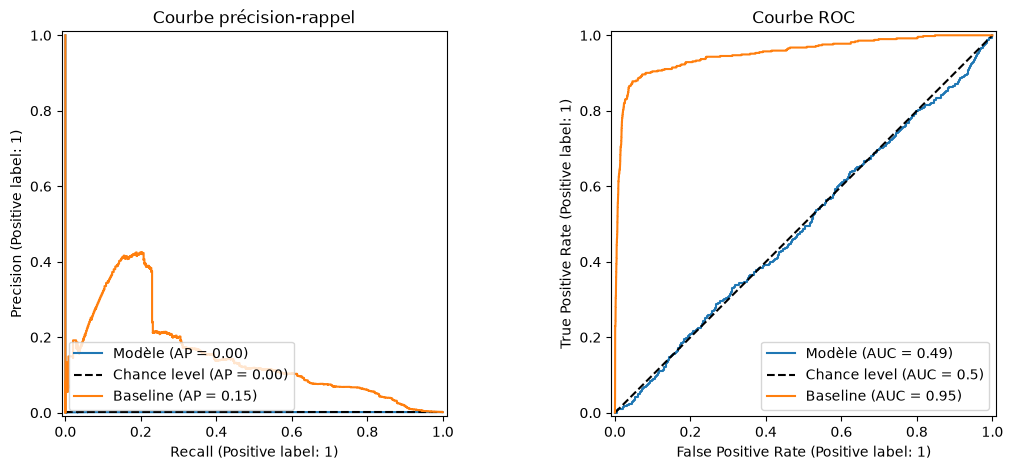

Précision moyenne (AP) : 0.0017 | ROC AUC : 0.4939
Baseline norme L2 : AP = 0.1479, ROC AUC = 0.9525


In [11]:
np.random.seed(0)
random_scores = np.random.rand(data.shape[0])
# NB : np.zeros(data.shape[0]) ne se diffuse pas contre une matrice (284807, 29) -> on utilise np.zeros(data.shape)
l2_baseline = reconstruction_error(data, np.zeros(data.shape))

print("Modèle = scores aléatoires, Baseline = norme L2")
display_pr_roc(data_labels, random_scores, l2_baseline)
print(f'Baseline norme L2 : AP = {average_precision_score(data_labels, l2_baseline):.4f}, '
      f'ROC AUC = {roc_auc_score(data_labels, l2_baseline):.4f}')

Sachant que les données proviennent d'une transformation PCA des données de transaction originales (auxquelles nous n'avons pas accès), pouvez-vous tenter d'expliquer le score non-nul obtenu par la 2e baseline ?

**Réponse :** les attributs `V1`…`V28` sont des composantes principales : elles sont centrées (moyenne nulle) et décorrélées entre elles. Après la normalisation centrée réduite, chaque attribut a en plus une variance de 1, si bien que la norme L2 d'une transaction mesure sa **distance au centre du nuage de points**, chaque direction étant pondérée par sa dispersion habituelle. C'est (à l'attribut `Amount` près) la distance de Mahalanobis dans l'espace des données d'origine, une mesure classique d'atypicité.

Les fraudes ont des comportements inhabituels et se retrouvent donc plus souvent loin du centre, d'où un score bien supérieur au hasard : AP = 0,148 contre 0,0017 pour les scores aléatoires (qui correspond simplement à la proportion de fraudes, 492 / 284 807), et une aire ROC de 0,95 contre 0,5. Cette baseline n'est toutefois pas parfaite : de nombreuses transactions légitimes sont aussi extrêmes (par ex. des montants très élevés) et passent devant les fraudes dans le classement.

## 4. Définir des fonctions pour entraîner, valider, et évaluer des modèles

Veuillez définir une fonction `train` qui entraîne un *modèle* (que vous créerez plus bas avec Keras) sur un jeu de *données*, avec l'objectif de reconstruire les données (donc les données d'entrée et de sortie pour un entraînement supervisé sont identiques).  Toutes les *x* époques d'entraînement (`epochs_per_iteration`) la fonction `train` affiche les scores de *précision moyenne* et de *aire sous la courbe ROC*, mais pas les graphiques.  La fonction itère cela *y* fois (`nb_iterations`).

Veuillez définir aussi une fonction `evaluate` qui affiche les courbes précision-rappel et ROC pour un modèle, et inclut dans chaque graphique la *baseline* de la norme L2 des données initiales (2e baseline de la section 3).

Vous pouvez utiliser ces [méthodes de Keras](https://keras.io/api/models/model_training_apis) :
   * [model.fit(...)](https://keras.io/api/models/model_training_apis/#fit-method) pour lancer un certain nombre de pas d'entraînement (*backward pass*)
   * [model.predict(...)](https://keras.io/api/models/model_training_apis/#predict-method) pour exécuter le modèle sur des données et obtenir la sortie (*forward pass*)

In [12]:
total_epochs = {}  # nombre total d'époques effectuées par chaque modèle (clé : model.name)

def train(model, data, epochs_per_iteration = 10, nb_iterations = 10):
    '''
    Entraîne l'autoencodeur à reconstruire `data` (entrée = sortie).  Toutes les `epochs_per_iteration`
    époques, affiche la précision moyenne et l'aire sous la courbe ROC de la détection de fraudes
    (étiquettes prises dans la variable globale `data_labels`, uniquement pour l'évaluation).
    Plusieurs appels successifs poursuivent l'entraînement du même modèle.
    '''
    for i in range(nb_iterations):
        history = model.fit(data, data, epochs=epochs_per_iteration, batch_size=256, shuffle=True, verbose=0)
        total_epochs[model.name] = total_epochs.get(model.name, 0) + epochs_per_iteration
        rec_errors = reconstruction_error(data, model.predict(data, batch_size=4096, verbose=0))
        ap = average_precision_score(data_labels, rec_errors)
        auc = roc_auc_score(data_labels, rec_errors)
        print(f"Itération {i + 1:2d}/{nb_iterations} | époques : {total_epochs[model.name]:3d} | "
              f"loss : {history.history['loss'][-1]:.4f} | AP : {ap:.4f} | ROC AUC : {auc:.4f}")

In [13]:
def evaluate(model, data, data_labels):
    '''
    Affiche les courbes précision-rappel et ROC du modèle, avec la baseline de la norme L2.
    Affiche aussi la précision maximale (hors point trivial à rappel nul) et le rappel correspondant.
    Retourne (précision moyenne, aire sous la courbe ROC).
    '''
    rec_errors = reconstruction_error(data, model.predict(data, batch_size=4096, verbose=0))
    baseline = reconstruction_error(data, np.zeros(data.shape))
    print(f'Modèle {model.name} entraîné pendant {total_epochs.get(model.name, 0)} époques au total')
    ap, auc = display_pr_roc(data_labels, rec_errors, baseline)

    precision, recall, _ = precision_recall_curve(data_labels, rec_errors)
    precision, recall = precision[:-1], recall[:-1]  # le dernier point (P=1, R=0) est conventionnel
    best = np.argmax(precision)
    print(f'Précision maximale : {precision[best]:.3f} atteinte pour un rappel de {recall[best]:.3f}')
    for r in (0.1, 0.2, 0.5):
        print(f'  précision pour un rappel >= {r:.1f} : {precision[recall >= r].max():.3f}')
    return ap, auc

## 5. Créer, entraîner et évaluer des autoencodeurs 

### 5.1. Autoencodeur simple à trois couches

Veuillez définir en Keras un autoencodeur à trois couches, avec une couche de codage ayant une dimension plus faible que celle d'entrée (*undercomplete autoencoder*).  Utiliser un modèle de type `Sequential()` avec des couches entièrement connectées de type `Dense()`, en vous guidant sur les [exemples de Keras](https://keras.io/api/models/sequential/).  Choisissez une fonction de coût (*loss*) et un optimiseur appropriés.  N'oubliez pas de [compiler le modèle](https://keras.io/api/models/model_training_apis/#compile-method) à la fin.

In [14]:
input_dim = data.shape[1]  # 29 attributs (V1..V28 + Amount)
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(input_dim,)),
    keras.layers.Dense(8, activation='tanh', name='code'),           # couche de codage : 29 -> 8
    keras.layers.Dense(input_dim, activation='linear', name='sortie')  # sortie linéaire : données centrées réduites
], name='AE_3_couches')

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "AE_3_couches"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ code (Dense)                    │ (None, 8)              │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sortie (Dense)                  │ (None, 29)             │           261 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 501 (1.96 KB)

 Trainable params: 501 (1.96 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# model.save('modele_1.keras')  # enregistrer le modèle (Keras 3 : format .keras plutôt que .h5)
# del model  # supprimer le modèle de la mémoire
# model = keras.models.load_model('modele_1.keras') # charger le modèle

Veuillez entraîner le modèle avec la fonction `train` que vous avez définie plus haut.  Selon vos résultats intermédiaires, écrivez ici la commande qui semble suffisante pour atteindre le maximum de performance, et affichez ses résultats.  Notez que le modèle est sauvegardé, donc plusieurs appels à `train` permettent de continuer l'entraînement.  Dans votre rapport final, indiquez explicitement la durée totale en nombre d'époques.

In [16]:
train(model, data, 5, 6)  # 30 époques au total : le score est stable dès ~5-10 époques

Itération  1/6 | époques :   5 | loss : 0.7013 | AP : 0.1636 | ROC AUC : 0.9546


Itération  2/6 | époques :  10 | loss : 0.6974 | AP : 0.1644 | ROC AUC : 0.9549


Itération  3/6 | époques :  15 | loss : 0.6962 | AP : 0.1643 | ROC AUC : 0.9550


Itération  4/6 | époques :  20 | loss : 0.6955 | AP : 0.1642 | ROC AUC : 0.9551


Itération  5/6 | époques :  25 | loss : 0.6950 | AP : 0.1651 | ROC AUC : 0.9553


Itération  6/6 | époques :  30 | loss : 0.6947 | AP : 0.1645 | ROC AUC : 0.9554


Veuillez afficher les deux courbes (y compris les *baselines*), et les scores du modèle avec la fonction `evaluate`.

Modèle AE_3_couches entraîné pendant 30 époques au total


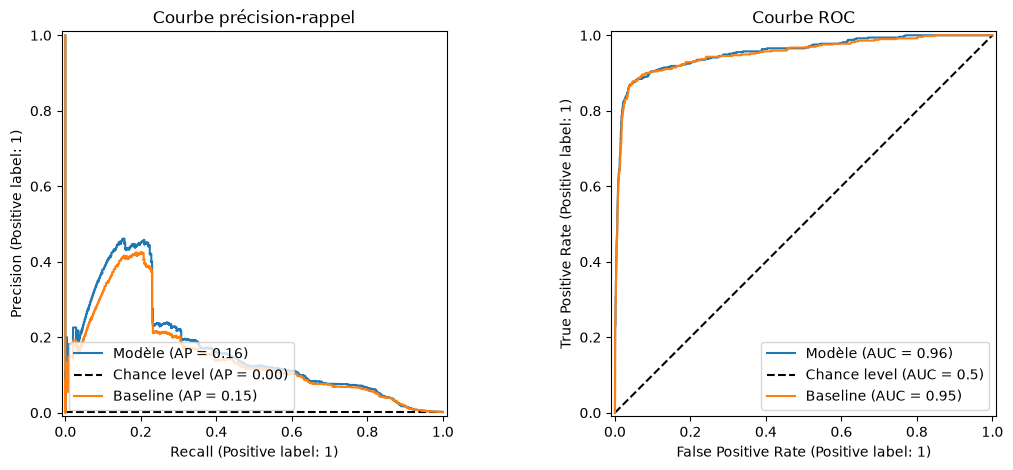

Précision moyenne (AP) : 0.1645 | ROC AUC : 0.9554
Précision maximale : 0.461 atteinte pour un rappel de 0.157
  précision pour un rappel >= 0.1 : 0.461
  précision pour un rappel >= 0.2 : 0.458
  précision pour un rappel >= 0.5 : 0.125


(0.16449715727115252, 0.9553856802307186)

In [17]:
evaluate(model, data, data_labels)

**Veuillez discuter vos résultats.**  Comment jugez-vous la capacité du modèle à détecter des transactions frauduleuses, compte tenu du fait qu'il n'a jamais été entraîné de manière supervisée ?  Comment se compare-t-il avec la baseline ?  Quelle est sa précision maximale, et pour quel rappel est-elle atteinte ?  (Approximativement, d'après le graphique.)  Comment interprétez-vous ces valeurs ?

**Discussion (modèle 1 : 29 → 8 → 29, *tanh*, 30 époques au total)**

* **Convergence.** La loss et les scores sont stables dès ~5 à 10 époques (AP ≈ 0,164, ROC AUC ≈ 0,955) : `train(model, data, 5, 6)`, soit **30 époques**, suffit largement ; continuer n'apporte rien.
* **Capacité de détection.** Sans jamais avoir vu une seule étiquette, le modèle obtient une précision moyenne de **0,164**, soit environ **95 fois** mieux que le hasard (0,0017). L'aire ROC de 0,955 paraît excellente, mais elle est trompeuse ici : avec 0,17 % de fraudes, même un faible taux de faux positifs représente un très grand nombre de transactions légitimes, ce que la courbe précision-rappel montre bien mieux.
* **Comparaison à la baseline.** Le gain sur la norme L2 est faible (AP 0,164 contre 0,148 ; ROC 0,955 contre 0,952). C'est cohérent : les données étant déjà des composantes PCA, un autoencodeur à une couche cachée se comporte presque comme une ACP. Il conserve les ~8 directions qui expliquent le mieux les données, et son erreur de reconstruction correspond à peu près à la norme des composantes restantes, une mesure très proche de la baseline L2.
* **Précision maximale.** Elle vaut environ **0,46** pour un rappel d'environ **0,16 à 0,2** : parmi les transactions les plus mal reconstruites, à peu près une sur deux est une fraude, ce qui permet d'en détecter environ 15 à 20 %. Pour détecter la moitié des fraudes (rappel 0,5), la précision tombe à ~0,125, soit environ 7 fausses alertes pour 1 vraie fraude.
* **Interprétation.** Ce modèle est utile comme outil de tri (classer les transactions à faire vérifier par un humain), pas comme détecteur automatique : les fraudes sont bien plus « atypiques » que la moyenne, mais une grande partie des transactions atypiques est légitime.

### 5.2. Autoencodeur à cinq couches

Veuillez définir maintenant un autoencodeur à cinq couches, sur le même principe que le précédent, toujours *undercomplete*.  Effectuez son entraînement et son évaluation finale, comme pour le modèle à 3 couches.

In [18]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(input_dim,)),
    keras.layers.Dense(20, activation='tanh', name='encodeur'),
    keras.layers.Dense(8, activation='tanh', name='code'),            # même taille de code que le modèle 1
    keras.layers.Dense(20, activation='tanh', name='decodeur'),
    keras.layers.Dense(input_dim, activation='linear', name='sortie')
], name='AE_5_couches')

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "AE_5_couches"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encodeur (Dense)                │ (None, 20)             │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Dense)                    │ (None, 8)              │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decodeur (Dense)                │ (None, 20)             │           180 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sortie (Dense)                  │ (None, 29)             │           609 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,557 (6.08 KB)

 Trainable params: 1,557 (6.08 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
train(model, data, 5, 6)  # 30 époques au total

Itération  1/6 | époques :   5 | loss : 0.5501 | AP : 0.0969 | ROC AUC : 0.9547


Itération  2/6 | époques :  10 | loss : 0.4870 | AP : 0.0738 | ROC AUC : 0.9547


Itération  3/6 | époques :  15 | loss : 0.4543 | AP : 0.0675 | ROC AUC : 0.9555


Itération  4/6 | époques :  20 | loss : 0.4361 | AP : 0.0683 | ROC AUC : 0.9583


Itération  5/6 | époques :  25 | loss : 0.4201 | AP : 0.0726 | ROC AUC : 0.9607


Itération  6/6 | époques :  30 | loss : 0.4076 | AP : 0.0704 | ROC AUC : 0.9609


In [20]:
model.save('modele_2.keras')  # enregistrer le modèle (Keras 3 : format .keras plutôt que .h5)
# del model  # supprimer le modèle de la mémoire
# model = keras.models.load_model('modele_2.keras') # charger le modèle

Modèle AE_5_couches entraîné pendant 30 époques au total


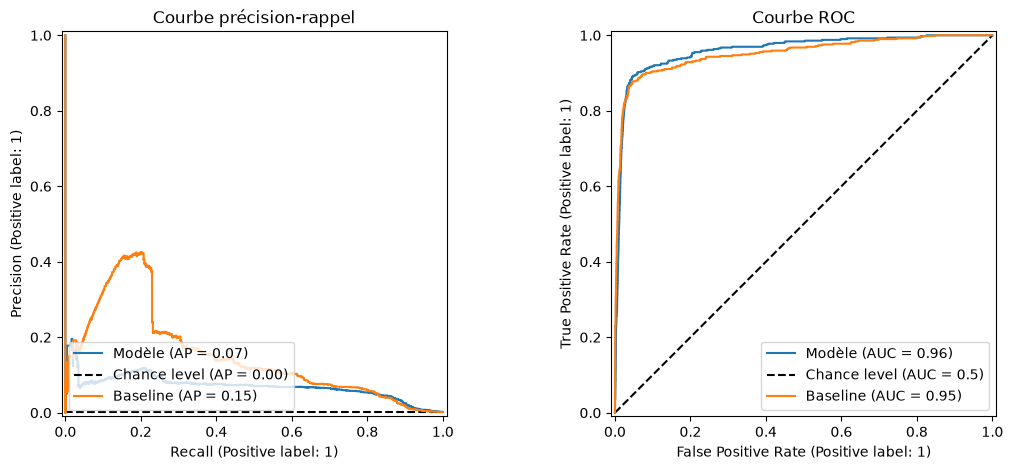

Précision moyenne (AP) : 0.0704 | ROC AUC : 0.9609
Précision maximale : 0.196 atteinte pour un rappel de 0.018
  précision pour un rappel >= 0.1 : 0.119
  précision pour un rappel >= 0.2 : 0.119
  précision pour un rappel >= 0.5 : 0.072


(0.07041019787516731, 0.9608570177729985)

In [21]:
evaluate(model, data, data_labels)

Veuillez discuter vos résultats et les comparer avec les précédents.

**Discussion (modèle 2 : 29 → 20 → 8 → 20 → 29, *tanh*, 30 époques au total)**

* **Résultats.** La loss de reconstruction est nettement meilleure que celle du modèle 1 (0,41 contre 0,69), mais la détection est **moins bonne** : l'AP passe de 0,097 après 5 époques à ~0,07 après 30 époques, en dessous du modèle 1 (0,164) et même de la baseline L2 (0,148). La précision maximale n'est que de **~0,2**, atteinte pour un rappel très faible (~0,02), et reste à ~0,12 au-delà. L'aire ROC est légèrement plus élevée (0,961), mais le haut du classement, celui qui compte en pratique, est moins bon.
* **Interprétation.** Plus de couches non linéaires donnent plus de capacité : le réseau apprend à reconstruire non seulement les transactions typiques mais aussi une partie des atypiques, fraudes comprises. L'erreur de reconstruction devient alors moins discriminante. C'est le cœur de la méthode : l'objectif optimisé (bien reconstruire) n'est pas l'objectif visé (mal reconstruire les fraudes), et au-delà d'un certain point, mieux reconstruire nuit à la détection. Le haut du classement est ici occupé par des transactions légitimes extrêmes (par ex. de très gros montants), qui restent difficiles à reconstruire.
* **Conclusion.** Un modèle plus profond n'est pas meilleur pour cette tâche. On pourrait arrêter l'entraînement plus tôt (meilleur AP après 5 époques), mais choisir ce moment demanderait les étiquettes, ce qui contredit le cadre non supervisé.

### 5.3. Autoencodeur à trois couches, *overcomplete*, avec *sparsity*
Veuillez enfin définir un autoencodeur à trois couches, mais avec une couche cachée ayant une dimension supérieure à celle des couches d'entrée et de sortie.  Afin d'éviter la pure copie entrée/sortie, ajoutez une contrainte de régularisation sur la couche cachée, qui limite la somme des valeurs absolues des activations dans cette couche (voir la [documentation](https://keras.io/api/layers/regularizers/) de Keras).

In [22]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(input_dim,)),
    # couche cachée plus grande que l'entrée (29 -> 64) ; la pénalité L1 sur les activations
    # (somme des valeurs absolues, ajoutée à la loss) force la plupart des neurones à rester à 0
    keras.layers.Dense(64, activation='relu', name='code',
                       activity_regularizer=keras.regularizers.L1(1e-3)),
    keras.layers.Dense(input_dim, activation='linear', name='sortie')
], name='AE_overcomplete_sparse')

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "AE_overcomplete_sparse"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ code (Dense)                    │ (None, 64)             │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sortie (Dense)                  │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,805 (14.86 KB)

 Trainable params: 3,805 (14.86 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
train(model, data, 5, 8)  # 40 époques au total

Itération  1/8 | époques :   5 | loss : 0.0206 | AP : 0.2780 | ROC AUC : 0.9409


Itération  2/8 | époques :  10 | loss : 0.0113 | AP : 0.3842 | ROC AUC : 0.9304


Itération  3/8 | époques :  15 | loss : 0.0088 | AP : 0.4549 | ROC AUC : 0.9256


Itération  4/8 | époques :  20 | loss : 0.0067 | AP : 0.4960 | ROC AUC : 0.9365


Itération  5/8 | époques :  25 | loss : 0.0061 | AP : 0.5332 | ROC AUC : 0.9453


Itération  6/8 | époques :  30 | loss : 0.0051 | AP : 0.6092 | ROC AUC : 0.9458


Itération  7/8 | époques :  35 | loss : 0.0046 | AP : 0.6273 | ROC AUC : 0.9498


Itération  8/8 | époques :  40 | loss : 0.0050 | AP : 0.6908 | ROC AUC : 0.9662


In [24]:
# model.save('modele_3.keras')  # enregistrer le modèle
# del model  # supprimer le modèle de la mémoire
# model = keras.models.load_model('modele_3.keras') # charger le modèle

Modèle AE_overcomplete_sparse entraîné pendant 40 époques au total


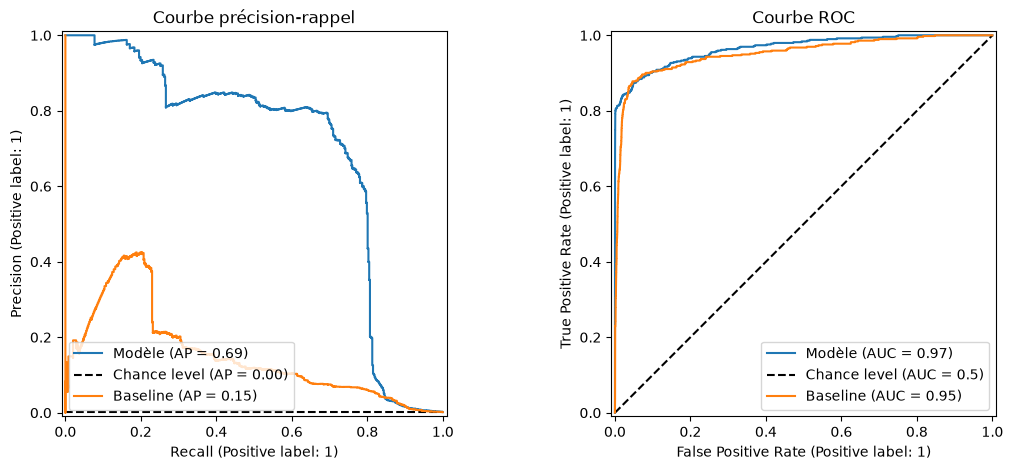

Précision moyenne (AP) : 0.6908 | ROC AUC : 0.9662
Précision maximale : 1.000 atteinte pour un rappel de 0.077
  précision pour un rappel >= 0.1 : 0.988
  précision pour un rappel >= 0.2 : 0.935
  précision pour un rappel >= 0.5 : 0.837


(0.6908360743974806, 0.966200205343066)

In [25]:
evaluate(model, data, data_labels)

Veuillez discuter vos résultats et les comparer avec les précédents.

**Discussion (modèle 3 : 29 → 64 → 29, *ReLU* + régularisation L1 des activations (λ = 10⁻³), 40 époques au total)**

* **Résultats.** C'est de loin le meilleur modèle : **AP = 0,69** et **ROC AUC = 0,966**, soit plus de 4 fois l'AP de la baseline L2 et du modèle 1. La précision maximale est de **1,0** jusqu'à un rappel d'environ **0,08** (une quarantaine de fraudes détectées sans aucune fausse alerte). Elle reste à ~0,99 pour un rappel de 0,1, ~0,94 pour 0,2 et encore **~0,84 pour un rappel de 0,5** : la moitié des fraudes sont détectées avec moins d'une fausse alerte sur six. La précision reste proche de 0,8 jusqu'à un rappel d'environ 0,75, puis s'effondre : les ~20 % de fraudes restantes ressemblent à des transactions normales et ne peuvent pas être détectées par cette approche.
* **Interprétation.** La couche cachée (64 neurones) est plus grande que l'entrée : avec des ReLU, le réseau pourrait reproduire exactement l'identité (x = ReLU(x) − ReLU(−x) ne demande que 2 × 29 = 58 neurones). La pénalité L1 rend toutefois chaque activation coûteuse. Le réseau reconstruit donc très finement les valeurs habituelles (loss de reconstruction très faible, ~0,005), mais il « rétrécit » les valeurs extrêmes, qui demanderaient de grandes activations. Les transactions dont les valeurs sortent des plages habituelles, ce qui est typiquement le cas des fraudes, sont alors mal reconstruites et ressortent nettement.
* **Durée d'entraînement.** L'AP croît jusqu'à ~40 époques (`train(model, data, 5, 8)`). Un essai séparé sur 100 époques n'a montré aucun gain au-delà, seulement des oscillations (AP entre ~0,56 et ~0,69) : **40 époques** suffisent.
* **Limites.** L'apprentissage est instable : d'une itération à l'autre, et surtout d'une initialisation à l'autre (graine aléatoire), l'AP varie fortement. Avec d'autres graines, nous avons observé des valeurs finales entre ~0,4 et ~0,68. Le résultat dépend aussi beaucoup de λ : à 10⁻⁵ la régularisation est trop faible et le réseau recopie tout, fraudes comprises (AP < 0,05). Enfin, λ et le nombre d'époques ont été choisis en regardant l'AP, donc avec les étiquettes, ce qui rend ce score un peu optimiste.

**Synthèse**

| Modèle | Époques | AP | ROC AUC | Précision max (rappel) | Précision à rappel 0,5 |
|---|---|---|---|---|---|
| Aléatoire | – | 0,002 | 0,49 | – | – |
| Baseline norme L2 | – | 0,148 | 0,952 | – | – |
| AE 3 couches (29-8-29) | 30 | 0,164 | 0,955 | ~0,46 (~0,16) | ~0,13 |
| AE 5 couches (29-20-8-20-29) | 30 | 0,070 | 0,961 | ~0,20 (~0,02) | ~0,07 |
| AE overcomplete + L1 (29-64-29) | 40 | **0,691** | **0,966** | **1,0 (~0,08)** | **~0,84** |

Les autoencodeurs *undercomplete* font à peine mieux que la norme L2 (ou moins bien s'ils ont trop de capacité). En revanche, l'autoencodeur *overcomplete* rendu sparse par une pénalité L1 détecte une grande partie des fraudes avec une bonne précision, sans jamais avoir été entraîné de manière supervisée.

### Fin du laboratoire
Veuillez nettoyer le *notebook* et y inclure l'affichage des résultats de vos systèmes définitifs.  Ne pas effacer les logs d'entraînement et les graphiques.  Veuillez ensuite soumettre le *notebook* sur Cyberlearn.